# Stationarity, Autocorrelation, and Why We Forecast Returns

| Key              | Value |
|:-----------------|:------|
| **Course Codes** | BBT 4206 and BFS 4102 |
| **Course Names** | BBT 4206: Business Intelligence II (Week 7-9 of 13)<br>BFS 4102: Advanced Business Data Analytics (Week 1-3 of 13) |
| **Semester**     | September to December 2026 |
| **Lecturer**     | Allan Omondi |
| **Contact**      | aomondi@strathmore.edu |
| **Note**         | The lecture contains both theory and practice.<br/>This notebook forms part of the practice.<br/>It is intended for educational purposes only, and nothing in it is investment advice.<br/>Recommended citation: [BibTex](https://raw.githubusercontent.com/course-files/TimeSeriesForecastingandNeuralNetworks/refs/heads/main/RecommendedCitation.bib) |

## What you will learn in this notebook

By the end of this notebook you should be able to:

1. Recognise a stationary and a non-stationary series by eye, and confirm your judgement with the ADF and KPSS tests.
2. Apply differencing and the logarithm to make a series stationary, and explain what each one does.
3. Read an ACF and a PACF plot.
4. Explain why regressing one price on another can produce a "significant" relationship that is not real (spurious regression).
5. Explain why the rest of the lab forecasts **returns** and not prices.
6. Explain volatility clustering and why volatility is far easier to forecast than direction.

**Prerequisites:** Notebook 1, and the lecture slides on components of a time series and on stationarity (slides 90 to 110).

## Recall: What Is Stationarity?

A time series is (weakly) stationary when three things do not depend on **when** you look:

1. The **mean** stays around the same value.
2. The **variance** stays around the same value.
3. The **autocorrelation** (how today relates to the day before, or ten days before) depends only on the gap between the two days, not on the calendar date.

Why do we care? Most statistical forecasting methods, and the tests built on them, learn a relationship from the past and assume that it still holds in the future. If the mean and the spread keep drifting, a relationship learned from 2016 describes a different series from the one you are forecasting in 2026.

Our plan in this notebook is to take the closing price, show that it is not stationary, and then discover that the daily **return** is.

## Step 1: Set Up the Notebook

In [4]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

# Google Colab starts with an empty workspace, so we fetch the lab files first.
# On your own computer this block does nothing.
if "google.colab" in sys.modules and not os.path.exists("tslab"):
    subprocess.run(["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"], check=True)
    os.chdir("TimeSeriesForecastingandNeuralNetworks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")

Python interpreter: C:\Users\aomondi\Documents\GitHub\Teaching\TimeSeriesForecastingandNeuralNetworks\.venv\Scripts\python.exe
Python version    : 3.12.10


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tests and models from statsmodels and arch
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import seasonal_decompose
import statsmodels.api as sm
from arch import arch_model

from tslab import config
from tslab.data import load_market_data
from tslab.plots import plot_acf_pacf

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

## Step 2: Load the Data and Create the Series We Will Study

In [6]:
data = load_market_data()

price = data["Close"]                       # the closing price
log_price = np.log(price)                   # the logarithm of the price
price_change = price.diff().dropna()        # first difference of the price (in dollars)
log_return = log_price.diff().dropna()      # first difference of the log price = the log return

Loaded 2953 trading days of NVDA, 2015-01-02 to 2026-09-30, with 7 predictor series.


## Step 3: Look First

Before any test, look at the plot. The lecture lists the visual signs of a series that is **not** stationary: a trend, a spread that changes over time, and a repeating seasonal pattern.

We plot each series together with its **rolling mean** and **rolling standard deviation**, using a window of 63 trading days (about one quarter). If the series is stationary, both rolling lines should be roughly flat.

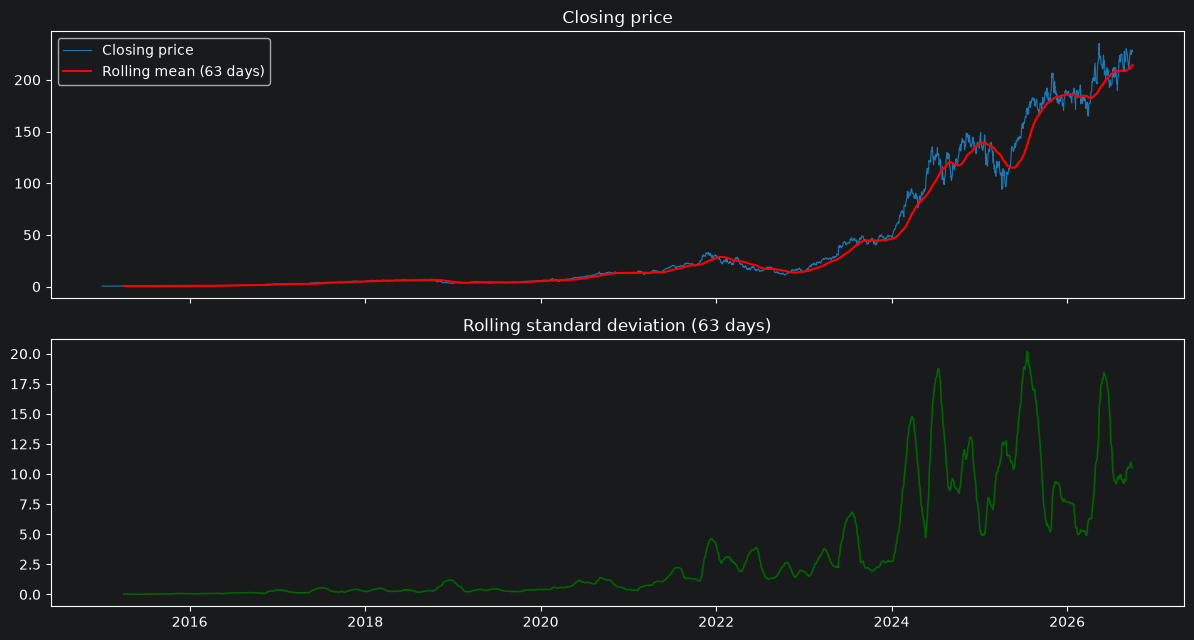

In [7]:
def plot_with_rolling(series, title, window=63):
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
    top.plot(series, color="tab:blue", linewidth=0.8, label=title)
    top.plot(series.rolling(window).mean(), color="red", linewidth=1.5, label=f"Rolling mean ({window} days)")
    top.legend(loc="upper left")
    top.set_title(title)
    bottom.plot(series.rolling(window).std(), color="darkgreen", linewidth=1.2)
    bottom.set_title(f"Rolling standard deviation ({window} days)")
    plt.tight_layout()
    plt.show()

plot_with_rolling(price, "Closing price")

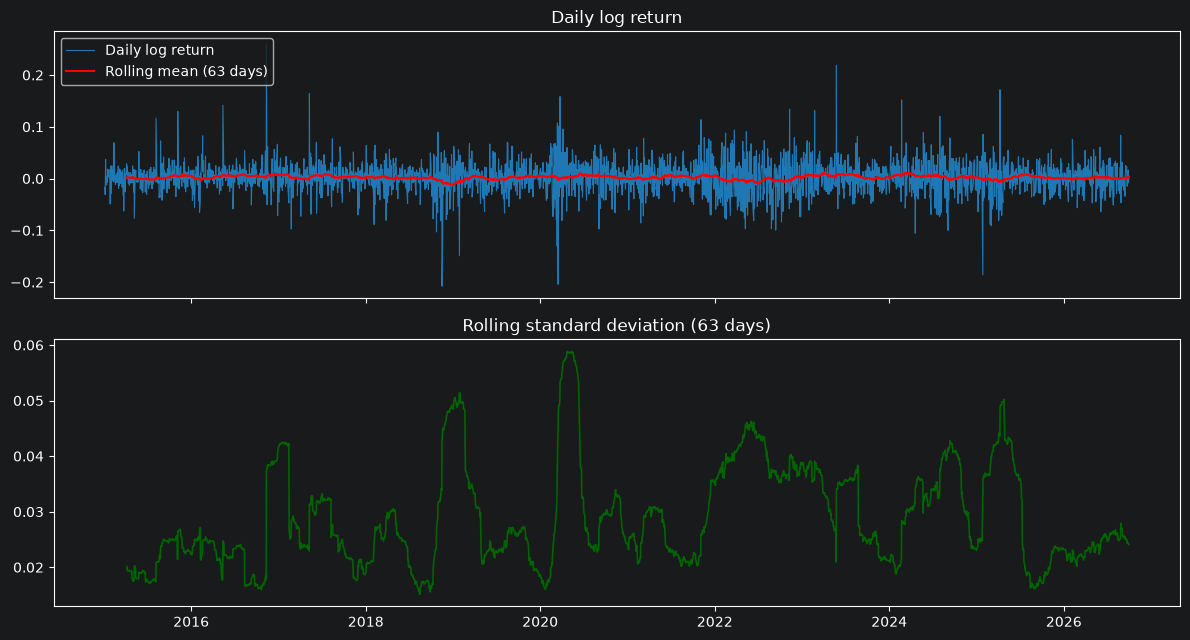

In [8]:
plot_with_rolling(log_return, "Daily log return")

Compare the two figures.

- The **price** climbs and falls over the years. Its rolling mean moves up and down with it, and the rolling spread is larger when the price level is higher. Neither is flat. This series is not stationary.
- The **return** fluctuates around zero. The rolling mean stays close to zero. The rolling standard deviation is **not perfectly flat** (it rises in turbulent periods), and we will come back to that in Step 8. But the series has a stable centre and does not wander away.

## Step 4: Test Statistically

Our eyes can be fooled, so we use two tests. They ask opposite questions on purpose.

| Test | Null hypothesis (H0) | Small p-value (below 0.05) means |
|:-----|:---------------------|:---------------------------------|
| **ADF** (Augmented Dickey-Fuller) | The series has a unit root (it is **non-stationary**) | Reject H0: the series looks **stationary** |
| **KPSS** (Kwiatkowski-Phillips-Schmidt-Shin) | The series is **stationary** | Reject H0: the series looks **non-stationary** |

Because the hypotheses are reversed, using both gives you a stronger conclusion:

| ADF says | KPSS says | Conclusion |
|:---------|:----------|:-----------|
| Stationary | Stationary | Stationary |
| Non-stationary | Non-stationary | Non-stationary |
| Stationary | Non-stationary | Difference stationary: differencing is needed (or, the series is stationary around a trend) |
| Non-stationary | Stationary | Trend stationary: remove the trend, or the test has little power in this sample |

(`autolag="AIC"` in the ADF test asks it to choose the number of lagged terms that best explains the data without overfitting.)

In [9]:
def stationarity_report(series, name):
    """Run the ADF and KPSS tests on one series and return a one-row summary."""
    adf_p = adfuller(series.dropna(), autolag="AIC")[1]
    kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[1]
    adf_says_stationary = adf_p < 0.05
    kpss_says_stationary = kpss_p >= 0.05
    if adf_says_stationary and kpss_says_stationary:
        verdict = "Stationary"
    elif not adf_says_stationary and not kpss_says_stationary:
        verdict = "Non-stationary"
    else:
        verdict = "Conflicting: look closer"
    return {"Series": name, "ADF p-value": adf_p, "KPSS p-value": kpss_p, "Verdict": verdict}

table = pd.DataFrame([
    stationarity_report(price, "Closing price"),
    stationarity_report(log_price, "Log of the closing price"),
    stationarity_report(price_change, "First difference of the price"),
    stationarity_report(log_return, "Log return (first difference of the log price)"),
]).set_index("Series")
table.round(4)

,ADF p-value,KPSS p-value,Verdict
Series,,,
Closing price,0.9987,0.01,Non-stationary
Log of the closing price,0.8208,0.01,Non-stationary
First difference of the price,0.0000,0.01,Conflicting: look closer
Log return (first difference of the log price),0.0000,0.10,Stationary


(KPSS p-values are reported between 0.01 and 0.10. A printed 0.01 means "0.01 or smaller", and 0.10 means "0.10 or larger".)

Read the table. The log transformation alone does **not** make a trending series stationary. It stabilises the variance (the spread no longer grows with the price level), but the series still wanders. **Differencing** removes the wandering. The log return is the difference of the log price, so it does both jobs at once.

This is why ARIMA has an "I" in its name. The "I" stands for **Integrated**: the model differences the series internally (the parameter `d`) so that the remaining series is stationary.

## Step 5: The Transformations from the Lecture

The lecture introduced four ways to make a series stationary. Let us apply each one to the closing price and test the result, so that you can see which ones work for **stock prices**.

In [10]:
# 1. Differencing: Y(t) - Y(t-1)
differenced = price.diff().dropna()

# 2. Detrending: fit a straight line through time, and subtract it
time_index = np.arange(len(price)).reshape(-1, 1)
trend_line = np.poly1d(np.polyfit(time_index.ravel(), price.values, deg=1))(time_index.ravel())
detrended = pd.Series(price.values - trend_line, index=price.index)

# 3. Log transformation: stabilises a variance that grows with the level
logged = np.log(price)

# 4. Seasonal differencing: Y(t) - Y(t-63), one quarter earlier
seasonal_differenced = price.diff(63).dropna()

# Combination used most often for prices: log, then difference
log_then_difference = np.log(price).diff().dropna()

pd.DataFrame([
    stationarity_report(price, "Original price"),
    stationarity_report(differenced, "Differenced"),
    stationarity_report(detrended, "Detrended (straight line removed)"),
    stationarity_report(logged, "Log transformed"),
    stationarity_report(seasonal_differenced, "Seasonal differenced (63 days)"),
    stationarity_report(log_then_difference, "Log, then differenced"),
]).set_index("Series").round(4)

,ADF p-value,KPSS p-value,Verdict
Series,,,
Original price,0.9987,0.01,Non-stationary
Differenced,0.0000,0.01,Conflicting: look closer
Detrended (straight line removed),0.9371,0.01,Non-stationary
Log transformed,0.8208,0.01,Non-stationary
Seasonal differenced (63 days),0.0000,0.01,Conflicting: look closer
"Log, then differenced",0.0000,0.10,Stationary


What to take from this table:

- **Detrending** removes a **deterministic** trend (a straight line). A stock's trend is **stochastic**: it does not follow a line, it drifts unpredictably. Subtracting a line therefore usually leaves a series that still wanders.
- **Seasonal differencing** is designed to remove a repeating pattern. A 63-day difference can pass the ADF test (for AAPL the KPSS test is borderline, so the verdict reads "conflicting"), but only because it is a long **change** in price, which is differencing again. There was no stable seasonal pattern to remove (we check this in Step 8).
- **Differencing** and **log then differencing** are the transformations that matter for prices.
- Differencing the dollar price gives a series whose spread still grows with the price level, which is why the log version is preferred.

**A warning on over-differencing.** If a series is already stationary, differencing it again makes it noisier and introduces artificial negative autocorrelation. Difference only as much as you need. For stock prices, one difference of the log is almost always enough.

## Step 6: Autocorrelation: Does Yesterday Help Predict Today?

The **autocorrelation function (ACF)** measures the correlation between a series and a copy of itself shifted by *k* days (the lag). The **partial autocorrelation function (PACF)** measures the same thing after removing the effect of the lags in between. These two plots are the tools you use to choose the `p` and `q` in an ARIMA model.

The blue band in each plot is an approximate 95 percent confidence band for "no autocorrelation". Bars that stay inside the band are indistinguishable from zero.

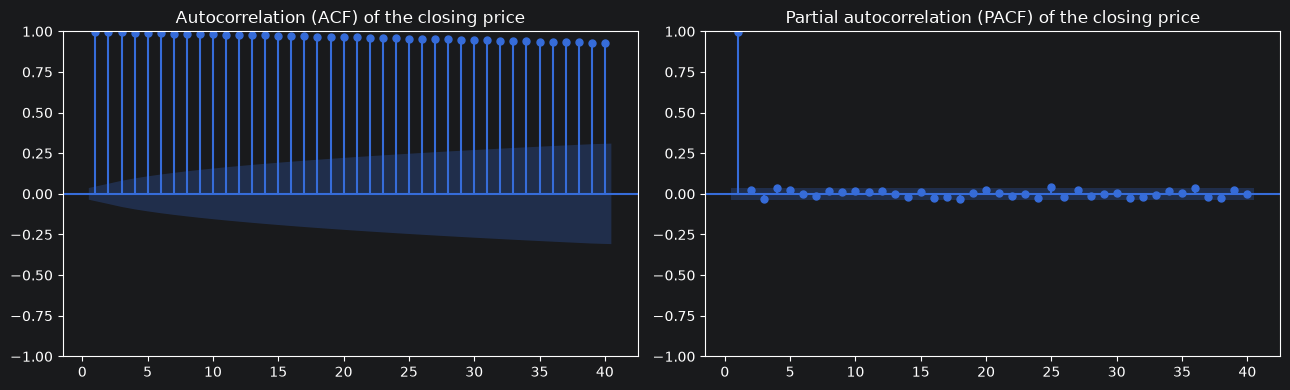

In [11]:
plot_acf_pacf(price, lags=40, title="of the closing price")

The ACF of the price decays very slowly and stays high for dozens of lags. That is the signature of a non-stationary series: today's price is strongly related to the price of almost every recent day, simply because the price drifts rather than jumping around.

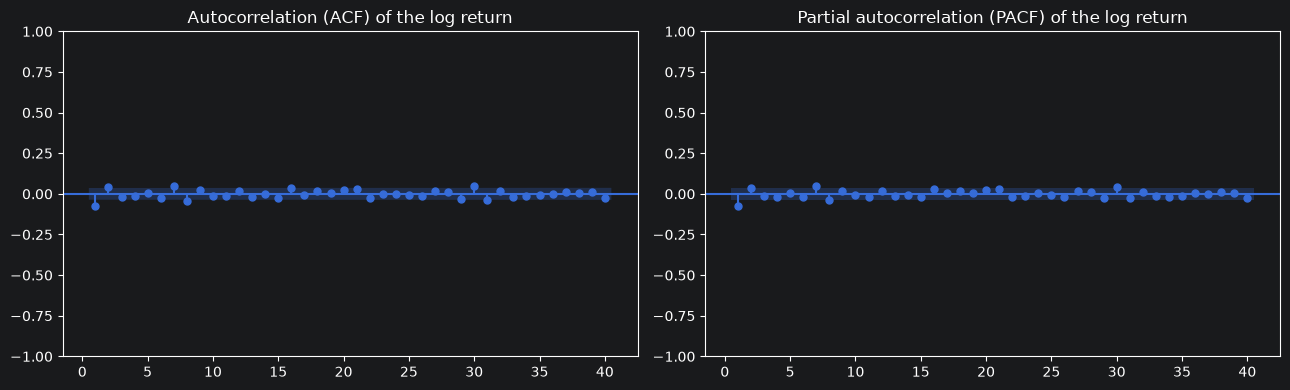

In [12]:
plot_acf_pacf(log_return, lags=40, title="of the log return")

For the daily return, count how many bars poke outside the band. With 40 lags, and a 95 percent band, you would expect about two bars to exceed it by chance alone even if the series had no structure at all. If you see roughly that many, and all the bars are tiny, the return has almost no linear memory. **Yesterday's return tells you very little about today's return.**

We can test that formally with the **Ljung-Box test**. Its null hypothesis is that there is no autocorrelation up to the stated lag. A small p-value means there is some.

In [13]:
lb = acorr_ljungbox(log_return, lags=[5, 10, 21], return_df=True)
lb.rename(columns={"lb_stat": "Statistic", "lb_pvalue": "p-value"})

,Statistic,p-value
5,22.034124,0.000516
10,39.943424,0.000017
21,53.777151,0.000106


Read this table carefully. The p-values at lags 10 and 21 are small, so the test does find some linear memory in the daily returns. That does **not** mean the returns are easy to forecast. With almost three thousand observations the test is powerful enough to detect very small correlations, and a correlation that is statistically detectable can still be too small to earn money after trading costs. Keep these numbers in mind, and compare their size with the table for the squared returns below.

### The same plot for the size of returns

Now look at the ACF of the **absolute** return and the **squared** return. These measure the size of a move and ignore its direction.

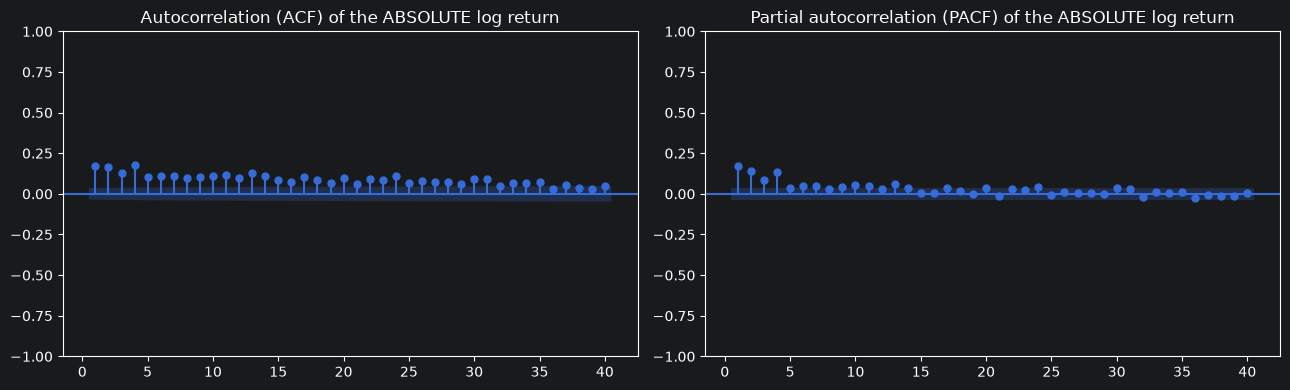

In [14]:
plot_acf_pacf(log_return.abs(), lags=40, title="of the ABSOLUTE log return")

In [15]:
lb_sq = acorr_ljungbox(log_return ** 2, lags=[5, 10, 21], return_df=True)
lb_sq.rename(columns={"lb_stat": "Statistic", "lb_pvalue": "p-value"})

,Statistic,p-value
5,103.125245,1.158979e-20
10,133.485817,9.072900e-24
21,180.686329,2.181568e-27


This is a very different picture. The autocorrelation of the **size** of returns is clearly positive for many lags. A big move today is followed by more big moves, in either direction. This is **volatility clustering**.

Put the two ideas together:

> The **direction** of tomorrow's return is almost unrelated to the past.
> The **size** of tomorrow's move is strongly related to the past.

This one finding explains much of what you will see in the remaining notebooks.

## Step 7: Spurious Regression, or Why We Do Not Regress Price on Price

Suppose a colleague regresses the price of the stock on the price of gold and reports a high R squared and a tiny p-value. Is that evidence that gold predicts the stock?

First, an experiment with **random numbers**. We generate 500 pairs of **independent** random walks. By construction, there is no relationship at all between the two series in a pair. We regress one on the other and record how often the slope looks "statistically significant".

In [16]:
rng = np.random.default_rng(config.SEED)
n_pairs, n_steps = 500, 1000
significant_levels, significant_changes = 0, 0
r2_levels = []

for _ in range(n_pairs):
    x = np.cumsum(rng.standard_normal(n_steps))   # a random walk
    y = np.cumsum(rng.standard_normal(n_steps))   # another, independent random walk

    fit_levels = sm.OLS(y, sm.add_constant(x)).fit()
    significant_levels += fit_levels.pvalues[1] < 0.05
    r2_levels.append(fit_levels.rsquared)

    fit_changes = sm.OLS(np.diff(y), sm.add_constant(np.diff(x))).fit()
    significant_changes += fit_changes.pvalues[1] < 0.05

print(f"Regressing LEVEL on LEVEL     : slope 'significant' in {significant_levels / n_pairs:.0%} of the pairs, average R squared {np.mean(r2_levels):.2f}")
print(f"Regressing CHANGE on CHANGE   : slope 'significant' in {significant_changes / n_pairs:.0%} of the pairs")
print("The honest rate, for series that are truly unrelated, is about 5%.")

Regressing LEVEL on LEVEL     : slope 'significant' in 92% of the pairs, average R squared 0.24
Regressing CHANGE on CHANGE   : slope 'significant' in 3% of the pairs
The honest rate, for series that are truly unrelated, is about 5%.


The result is striking. For unrelated random walks, a regression on the **levels** declares a "significant" relationship in the large majority of cases, while a regression on the **changes** behaves correctly (about 5 percent). This is the **spurious regression problem**: two series that drift will appear related, because both are drifting, not because one explains the other.

Now the same comparison with your real data: the stock against gold.

In [17]:
# Levels: log price on log price
levels = sm.OLS(np.log(data["Close"]), sm.add_constant(np.log(data["GOLD"]))).fit()

# Changes: daily log return on daily log return
stock_ret = np.log(data["Close"]).diff().dropna()
gold_ret = np.log(data["GOLD"]).diff().dropna()
changes = sm.OLS(stock_ret, sm.add_constant(gold_ret)).fit()

print(f"Levels : R squared = {levels.rsquared:.3f}   p-value of the slope = {levels.pvalues.iloc[1]:.2e}")
print(f"Changes: R squared = {changes.rsquared:.4f}   p-value of the slope = {changes.pvalues.iloc[1]:.2e}")

Levels : R squared = 0.828   p-value of the slope = 0.00e+00
Changes: R squared = 0.0015   p-value of the slope = 3.58e-02


Compare the two R squared values. The regression on levels is likely to look impressive, and the regression on daily changes is likely to look weak. Which one tells you something about whether **today's gold move helps forecast the stock**? Only the second. The first is mostly two trends keeping each other company.

**The lesson for the lab:** every predictor we use in the next notebooks enters the model as a **return or a change**, never as a price level. (The exceptions are the VIX and the interest rate. They hover around a level instead of drifting away, so a level carries meaning, and Notebook 4 gives you the chance to test whether it does.)

## Step 8: Seasonality, Revisited

The lecture covered seasonal models (Holt-Winters, SARIMA) at length. Do daily stock prices have a seasonal pattern worth modelling? We decompose the log price into trend, seasonal and residual components, using a seasonal period of 21 trading days (about one month), and compare the **size** of the three parts.

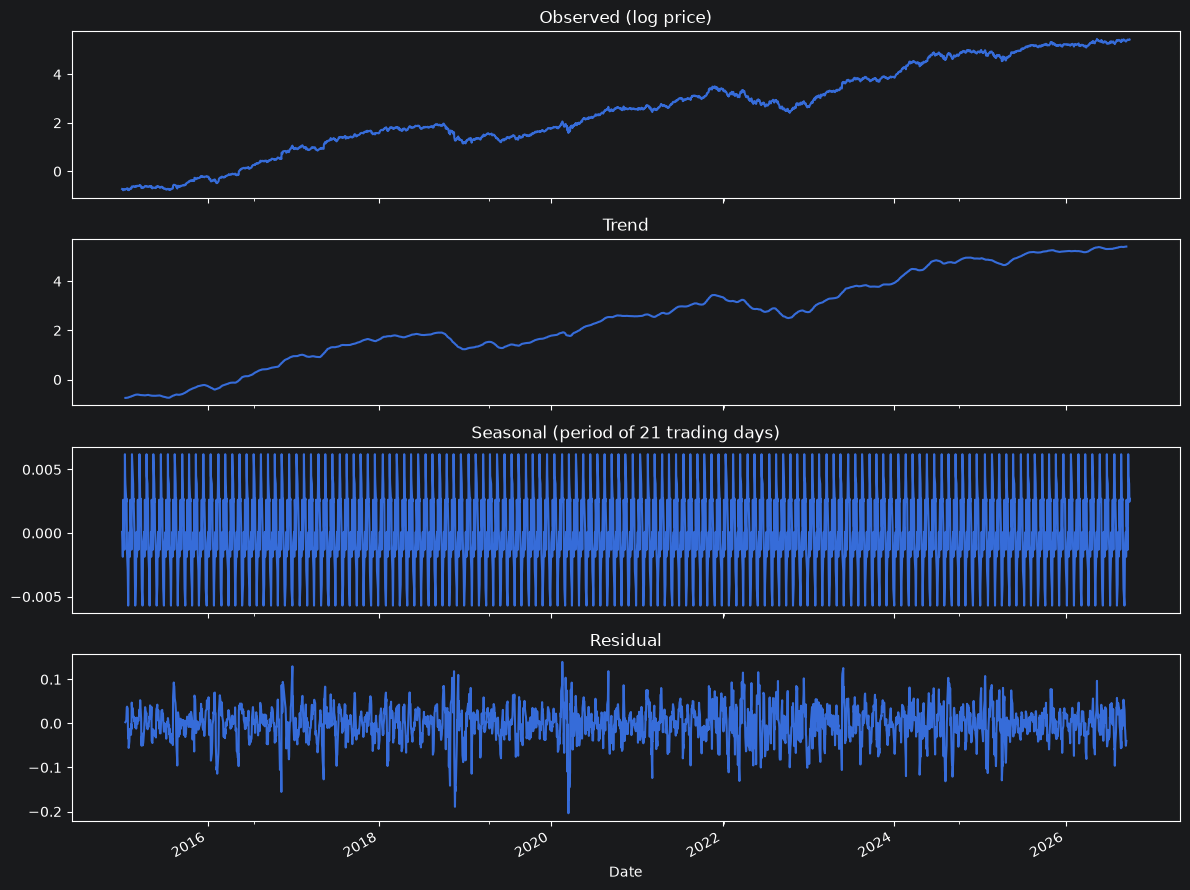

Range of the trend component   : 6.151
Range of the seasonal component: 0.012
Range of the residual          : 0.343


In [18]:
decomposition = seasonal_decompose(np.log(price), model="additive", period=21)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
decomposition.observed.plot(ax=axes[0], title="Observed (log price)")
decomposition.trend.plot(ax=axes[1], title="Trend")
decomposition.seasonal.plot(ax=axes[2], title="Seasonal (period of 21 trading days)")
decomposition.resid.plot(ax=axes[3], title="Residual")
plt.tight_layout()
plt.show()

spread = lambda s: s.dropna().max() - s.dropna().min()
print(f"Range of the trend component   : {spread(decomposition.trend):.3f}")
print(f"Range of the seasonal component: {spread(decomposition.seasonal):.3f}")
print(f"Range of the residual          : {spread(decomposition.resid):.3f}")

Compare the three ranges. The seasonal component is tiny compared with the trend and the residual. The decomposition is forced to find a repeating 21-day shape, and what it finds is almost flat.

A calendar pattern, if it exists, would also show up as a different **average return** on certain weekdays or in certain months. We check that directly, and test whether any difference is bigger than random noise.

In [19]:
by_weekday = log_return.groupby(log_return.index.dayofweek).agg(["mean", "std", "count"])
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri"]
by_weekday["t-statistic"] = by_weekday["mean"] / (by_weekday["std"] / np.sqrt(by_weekday["count"]))
by_weekday.round(5)

,mean,std,count,t-statistic
Mon,0.00275,0.03159,552,2.04498
Tue,0.00208,0.02716,609,1.88999
Wed,0.00280,0.02863,606,2.40591
Thu,0.00247,0.03134,595,1.92250
Fri,0.00036,0.03171,590,0.27457


A t-statistic needs to be larger than about 2 in absolute size before you should take a difference seriously, and here you are comparing five weekdays, so one of them will exceed 2 by chance about one time in four. In our table, Monday and Wednesday both exceed 2, which is what the multiple comparisons problem warns about: two out of five is not surprising. This is the **multiple comparisons problem**. A pattern that you find by looking at many slices of the data is not evidence of a pattern until it also holds on data that you did not use to find it.

For daily stock prices, then, we do not expect Holt-Winters or SARIMA to find a **stable** seasonal pattern. We still include the calendar features in the forecasting models in the next notebooks, and let the data show whether they help.

## Step 9: Volatility Is Forecastable, Direction Mostly Is Not

We found in Step 6 that the **size** of returns clusters. The standard model for this is **GARCH(1,1)** (Generalised AutoRegressive Conditional Heteroskedasticity). "Heteroskedasticity" means that the variance is not constant. GARCH says that tomorrow's variance is a weighted combination of three things:

1. a long-run average variance,
2. yesterday's variance (volatility persists), and
3. yesterday's squared surprise (a big shock raises tomorrow's variance).

We fit it to the daily return in percent (the optimiser works better with numbers that are not tiny).

In [20]:
returns_pct = log_return * 100
garch = arch_model(returns_pct, mean="Constant", vol="GARCH", p=1, q=1, dist="t")
garch_fit = garch.fit(disp="off")
print(garch_fit.summary().tables[1])
print(garch_fit.summary().tables[2])

                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.2498  4.153e-02      6.016  1.790e-09 [  0.168,  0.331]
                             Volatility Model                             
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          0.2439      0.108      2.248  2.456e-02 [3.128e-02,  0.457]
alpha[1]       0.0797  2.172e-02      3.669  2.438e-04 [3.711e-02,  0.122]
beta[1]        0.8975  2.956e-02     30.363 1.671e-202   [  0.840,  0.955]


In the second table, `alpha[1]` is the reaction to yesterday's shock and `beta[1]` is the persistence of volatility. A large `beta[1]` (often above 0.8) means that volatility fades slowly. `nu` in the first table is the degrees of freedom of the Student t distribution. The smaller it is, the fatter the tails; we chose the t distribution because Notebook 1 showed that real returns have fat tails.

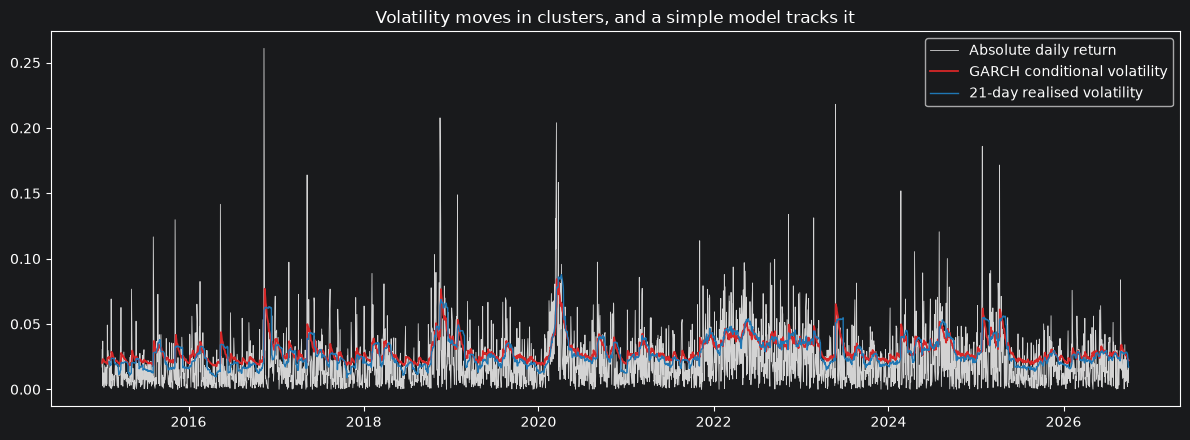

In [21]:
conditional_vol = garch_fit.conditional_volatility / 100        # back to return units
realised_vol = log_return.rolling(21).std()

plt.figure(figsize=(12, 4.5))
plt.plot(log_return.abs(), color="lightgrey", linewidth=0.6, label="Absolute daily return")
plt.plot(conditional_vol, color="tab:red", linewidth=1.3, label="GARCH conditional volatility")
plt.plot(realised_vol, color="tab:blue", linewidth=1, label="21-day realised volatility")
plt.legend()
plt.title("Volatility moves in clusters, and a simple model tracks it")
plt.tight_layout()
plt.show()

In [22]:
# Which is easier to predict from today's information: the NEXT day's direction, or the NEXT day's size?
next_return = log_return.shift(-1)
frame = pd.DataFrame({
    "today_return": log_return,
    "today_garch_vol": conditional_vol,
    "next_return": next_return,
    "next_abs_return": next_return.abs(),
}).dropna()

print("Correlation, today's return vs tomorrow's return        :", round(frame["today_return"].corr(frame["next_return"]), 3))
print("Correlation, today's GARCH volatility vs tomorrow's SIZE:", round(frame["today_garch_vol"].corr(frame["next_abs_return"]), 3))

Correlation, today's return vs tomorrow's return        : -0.072
Correlation, today's GARCH volatility vs tomorrow's SIZE: 0.248


Compare the two correlations. The first (direction) is small. The second (size) should be clearly positive.

(This is an in-sample illustration, because the GARCH parameters were estimated on the whole sample. The point is the difference between the two numbers, not their exact size.)

**This is the most important realistic expectation of the module.** Risk managers use volatility forecasts every day because they work. Predicting the **direction** of tomorrow's move is a much harder problem, which is the reason Notebook 4 compares every model to a naive forecast and tests whether any improvement is real.

## Step 10: Exercises

1. In Step 4, the ADF test on the closing price gives a large p-value and the test on the log return gives a tiny one. Explain in plain language what each result means for forecasting.
2. In Step 4 the log transformation alone did not make the price stationary. What did it achieve instead?
3. Repeat the spurious regression experiment in Step 7, but change `n_steps` to 100, then to 5000. What happens to the share of "significant" relationships? What does that tell you about using more data?
4. Choose any **other** predictor in the table in Notebook 1 and repeat the levels versus changes comparison in Step 7. Does the levels regression look equally impressive?
5. The lecture asked: "Which of the following series is stationary?" (the slide with the nine plots). Without looking at the answer, decide where the **log return of a stock** would sit in that slide, and justify it with the rolling statistics from Step 3.
6. Change the GARCH specification in Step 9 to `dist="normal"`. How do the parameters change, and which fit is better by the log-likelihood in the summary?

## Summary

- A price is **not** stationary. A return **is** (approximately).
- Use ADF and KPSS **together** because their hypotheses are opposite.
- Log stabilises variance. Differencing removes wandering. Detrending and seasonal differencing do not help much for stock prices.
- Regressing level on level can produce a convincing but meaningless result. Use returns and changes.
- The direction of returns has almost no linear memory, while the size of returns clusters. Volatility can be forecast; direction is hard.

**Therefore, from this point on, our target is the next-day log return, and we convert the forecast back to a closing price.**